# Análisis Exploratorio de Datos (AED): Rendimiento Histórico en la Premier League y el Rol del Director Técnico (1993 - 2026)
**Pre-entrega 2 - Data Science (Fundación YPF)**

### Objetivos de esta etapa:
1. Diagnosticar la calidad e integridad de los datos (+12.000 partidos a lo largo de 33 temporadas).
2. Examinar la evolución histórica de directores técnicos británicos vs. extranjeros.
3. Evaluar métricas clave de rendimiento (goles, tiros, ventaja de localía y puntos obtenidos).
4. Analizar la brecha competitiva orientada a la clasificación a la **UEFA Champions League (Top 4)**.

### Importación de Librerías y Configuración Gráfica

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilos visuales
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("Librerías cargadas exitosamente")

Librerías cargadas exitosamente


### Carga del Dataset Curado y Verificación Dimensional

In [8]:
# Cargar dataset
ruta = os.path.join("..", "data", "processed", "dataset_final_modelo.csv")
if not os.path.exists(ruta):
    ruta = "data/processed/dataset_final_modelo.csv"

df_raw = pd.read_csv(ruta, low_memory=False)

# Columnas clave para el análisis deportivo y técnico
cols_utiles = [
    'Date', 'HomeTeam', 'AwayTeam', 'temporada_origen',
    'FTHG', 'FTAG', 'FTR',
    'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR',
    'dt_home', 'nacionalidad_dt_home', 'es_britanico_dt_home',
    'dt_away', 'nacionalidad_dt_away', 'es_britanico_dt_away'
]

# Conservar solo las columnas existentes y crear copia limpia
df = df_raw[[c for c in cols_utiles if c in df_raw.columns]].copy()
df['Date'] = pd.to_datetime(df['Date'])

print(f"Dataset listo: {df.shape[0]} partidos y {df.shape[1]} variables seleccionadas.")

Dataset listo: 12614 partidos y 25 variables seleccionadas.


### Clasificación de Variables (Cualitativas vs. Cuantitativas)

In [10]:
# Variables esenciales para el análisis
cols_identificacion = ['HomeTeam', 'AwayTeam']
cols_dts = ['dt_home', 'nacionalidad_dt_home', 'es_britanico_dt_home',
            'dt_away', 'nacionalidad_dt_away', 'es_britanico_dt_away']
cols_resultado = ['FTHG', 'FTAG', 'FTR']
cols_juego = [c for c in ['HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR'] if c in df.columns]

print(f"• Variables de identificación: {len(cols_identificacion)}")
print(f"• Variables de dirección técnica: {len(cols_dts)}")
print(f"• Variables de resultado y marcador: {len(cols_resultado)}")
print(f"• Variables de estadísticas de partido: {len(cols_juego)}")

# Clasificación metodológica de variables
cualitativas_nominales = ['HomeTeam', 'AwayTeam', 'FTR', 'dt_home', 'dt_away', 'nacionalidad_dt_home', 'nacionalidad_dt_away']
cualitativas_binarias = ['es_britanico_dt_home', 'es_britanico_dt_away']
cuantitativas_discretas = [c for c in ['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR'] if c in df.columns]

print("--- CLASIFICACIÓN DE VARIABLES ---")
print(f"• Categóricas Nominales ({len(cualitativas_nominales)}): {cualitativas_nominales}")
print(f"• Categóricas Binarias ({len(cualitativas_binarias)}): {cualitativas_binarias}")
print(f"• Cuantitativas de Conteo ({len(cuantitativas_discretas)}): {cuantitativas_discretas}")

• Variables de identificación: 2
• Variables de dirección técnica: 6
• Variables de resultado y marcador: 3
• Variables de estadísticas de partido: 12
--- CLASIFICACIÓN DE VARIABLES ---
• Categóricas Nominales (7): ['HomeTeam', 'AwayTeam', 'FTR', 'dt_home', 'dt_away', 'nacionalidad_dt_home', 'nacionalidad_dt_away']
• Categóricas Binarias (2): ['es_britanico_dt_home', 'es_britanico_dt_away']
• Cuantitativas de Conteo (14): ['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']


### Diagnóstico de Valores Faltantes (MCAR / MAR / MNAR) y Outliers

En datasets históricos de fútbol, los valores faltantes responden a la evolución tecnológica del registro de datos:
* **Marcador y Resultado (`FTHG`, `FTAG`, `FTR`):** Presentes en el 100% de los registros desde 1993.
* **Estadísticas de juego (`HS`, `HST`, `Faltas`, etc.):** Ausentes en la década de 1990 porque la liga comenzó a recolectar datos de disparos y faltas a partir del año 2000. Son faltantes **MAR** (Missing at Random) condicionados por el año del encuentro.

In [11]:
# Reporte de valores nulos
tabla_nulos = pd.DataFrame({
    'Total Nulos': df.isna().sum(),
    'Porcentaje (%)': (df.isna().mean() * 100).round(2)
})
tabla_nulos = tabla_nulos[tabla_nulos['Total Nulos'] > 0].sort_values('Porcentaje (%)', ascending=False)
print("Variables con valores faltantes:")
display(tabla_nulos)

Variables con valores faltantes:


,Total Nulos,Porcentaje (%)
HS,2824,22.39
AS,2824,22.39
HST,2824,22.39
AST,2824,22.39
HF,2824,22.39
AF,2824,22.39
HC,2824,22.39
AC,2824,22.39
HY,2824,22.39
AY,2824,22.39


### Estadísticas descriptivas, Asimetría y Outliers (IQR)

Se evalúa la forma de las distribuciones cuantitativas (media vs. mediana, asimetría con .skew() y detección de valores atípicos)

In [12]:
# 1. Resumen numérico
display(df[['FTHG', 'FTAG']].describe().round(2))

# 2. Evaluación de Asimetría (Skewness)
skew_home = df['FTHG'].skew()
skew_away = df['FTAG'].skew()
print(f"Asimetría Goles Local: {skew_home:.2f} (Sesgo positivo/derecha)")
print(f"Asimetría Goles Visitante: {skew_away:.2f} (Sesgo positivo/derecha)")

# 3. Detección de partidos atípicos (IQR)
goles_partido = df['FTHG'] + df['FTAG']
q1 = goles_partido.quantile(0.25)
q3 = goles_partido.quantile(0.75)
iqr = q3 - q1
umbral_outlier = q3 + 1.5 * iqr

partidos_goleada = df[goles_partido > umbral_outlier]
print(f"Partidos con cantidad atípica de goles (> {umbral_outlier:.0f} goles): {len(partidos_goleada)} partidos.")

,FTHG,FTAG
count,12614.00,12614.00
mean,1.53,1.17
std,1.30,1.15
min,0.00,0.00
25%,1.00,0.00
50%,1.00,1.00
75%,2.00,2.00
max,9.00,9.00


Asimetría Goles Local: 0.97 (Sesgo positivo/derecha)
Asimetría Goles Visitante: 1.09 (Sesgo positivo/derecha)
Partidos con cantidad atípica de goles (> 8 goles): 32 partidos.


Visualización gráfica de la distribución (Histograma + Boxplot)

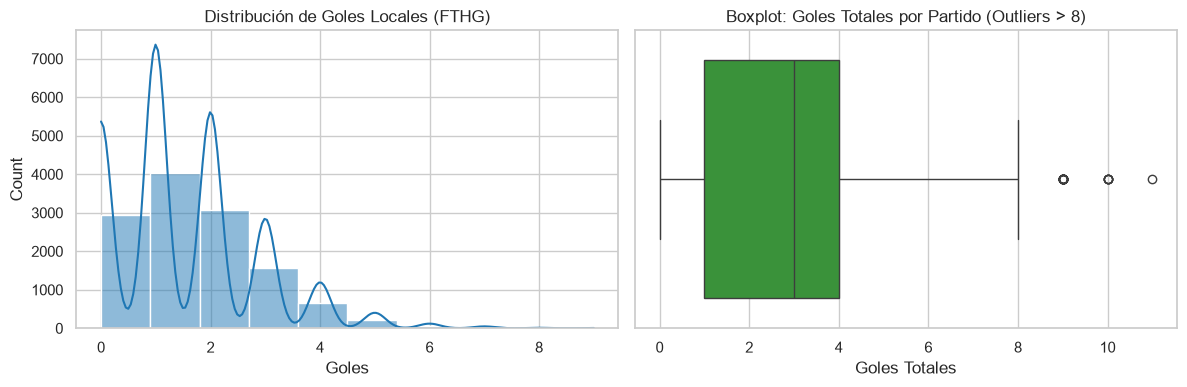

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma con KDE para ver el sesgo positivo
sns.histplot(df['FTHG'], bins=10, kde=True, ax=axes[0], color="#1f77b4")
axes[0].set_title("Distribución de Goles Locales (FTHG)")
axes[0].set_xlabel("Goles")

# Boxplot para visualizar los outliers detectados
sns.boxplot(x=df['FTHG'] + df['FTAG'], ax=axes[1], color="#2ca02c")
axes[1].set_title("Boxplot: Goles Totales por Partido (Outliers > 8)")
axes[1].set_xlabel("Goles Totales")

plt.tight_layout()
plt.show()

###  Análisis de Correlación Táctica y Tratamiento de Nulos (2000 - 2026)
Para analizar la correlación de disparos al arco (`HST`, `AST`), faltas y tiros totales sin sesgar los datos por los valores faltantes de los años 90 (MAR), creamos el subconjunto `df_tactico` a partir de la temporada 2000/2001. En este período disponemos de estadísticas de juego completas al 100%.

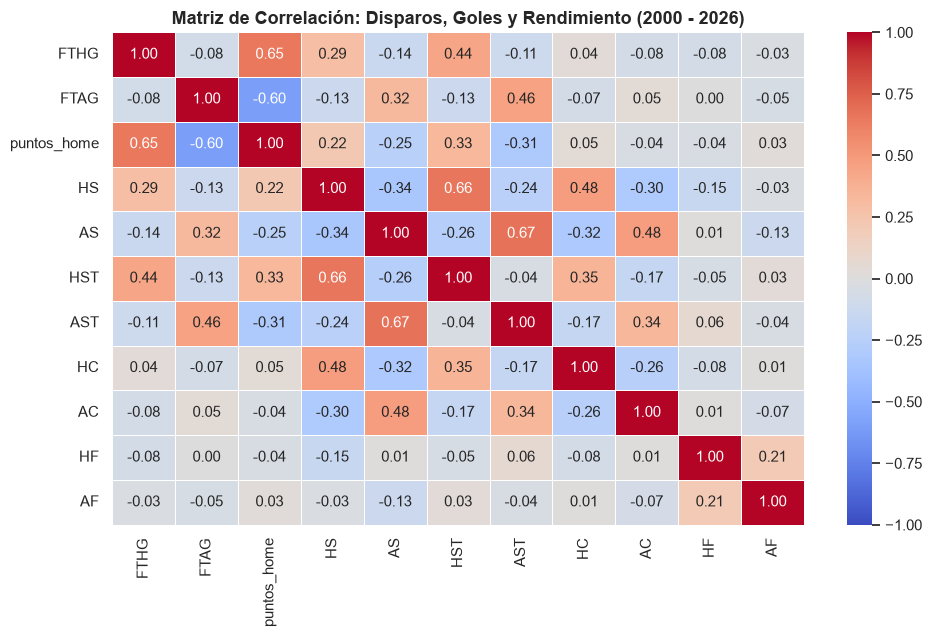

In [18]:
# Subconjunto táctico con estadísticas completas
df_tactico = df[df['Date'].dt.year >= 2000].copy()

# Seleccionar métricas numéricas para correlación
cols_corr = ['FTHG', 'FTAG', 'puntos_home', 'HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'HF', 'AF']
cols_corr_existentes = [c for c in cols_corr if c in df_tactico.columns]

matriz_corr = df_tactico[cols_corr_existentes].corr()

plt.figure(figsize=(10, 6.5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación: Disparos, Goles y Rendimiento (2000 - 2026)", fontsize=13, weight="bold")
plt.tight_layout()
plt.show()

### Gráficos clave del problema de negocio (Storytelling)
A partir de aquí se conecta la exploración con la hipótesis del proyecto (la presencia de entrenadores británicos y el rendimiento camino al Top 4):

Gráfico A: Evolución histórica del % de DTs británicos (1993 - 2026)

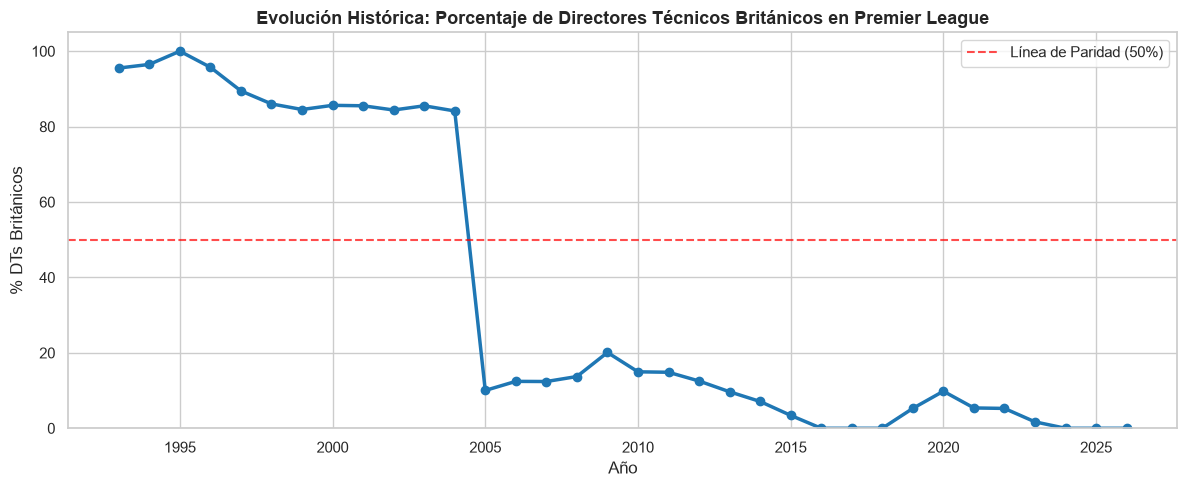

In [13]:
# Agrupar por año y calcular el porcentaje de DTs británicos
df['Año'] = df['Date'].dt.year
evolucion_dts = df.groupby('Año')['es_britanico_dt_home'].mean() * 100

plt.figure(figsize=(12, 5))
plt.plot(evolucion_dts.index, evolucion_dts.values, marker='o', color='#1f77b4', linewidth=2.5)
plt.axhline(50, color='red', linestyle='--', alpha=0.7, label='Línea de Paridad (50%)')
plt.title('Evolución Histórica: Porcentaje de Directores Técnicos Británicos en Premier League', fontsize=13, weight='bold')
plt.xlabel('Año')
plt.ylabel('% DTs Británicos')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

En los inicios de la Premier League (1993-1996), la presencia de directores técnicos británicos superaba el 90%. A partir de los años 2000 y especialmente con la consolidación del 'Big Six' (seis equipos con gran infraestructura económica y futbolista) en la década de 2010, se observa una caída pronunciada hacia valores cercanos al 30-40%. Esto confirma la globalización táctica de la liga.

Gráfico B: Ventaja de localía y efectividad según origen del DT

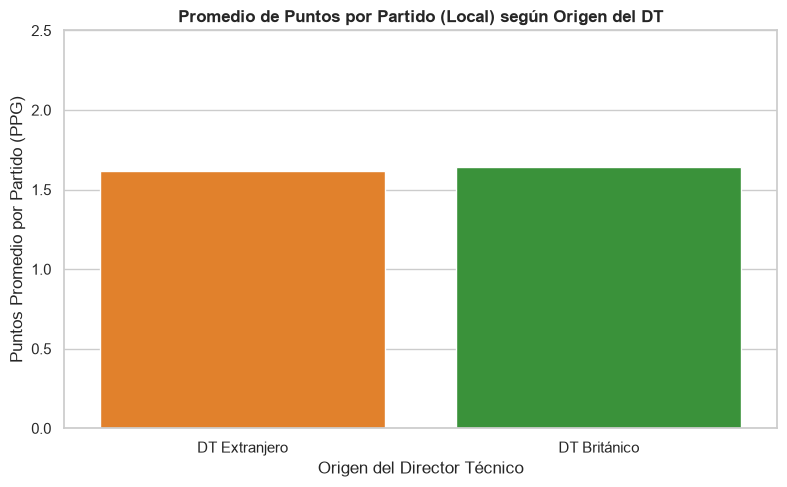

In [15]:
# Calcular puntos obtenidos por el equipo local (Victoria=3, Empate=1, Derrota=0)
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, 
    x='es_britanico_dt_home', 
    y='puntos_home', 
    hue='es_britanico_dt_home',
    estimator=np.mean, 
    errorbar=None, 
    palette=['#ff7f0e', '#2ca02c'],
    legend=False
)
plt.xticks([0, 1], ['DT Extranjero', 'DT Británico'])
plt.title('Promedio de Puntos por Partido (Local) según Origen del DT', fontsize=12, weight='bold')
plt.xlabel('Origen del Director Técnico')
plt.ylabel('Puntos Promedio por Partido (PPG)')
plt.ylim(0, 2.5)
plt.tight_layout()
plt.show()

Se puede apreciar que sus rendimientos de local son muy parejos a lo largo del tiempo

### Agregación a Nivel Temporada y Variables Objetivo

### Construcción de la Tabla de Temporada y Definición de Variables Target
Para predecir el desenlace de la liga de cara a la clasificación a la **UEFA Champions League**:
* **Regresión:** `puntos_totales` conseguidos por cada equipo en la temporada.
* **Clasificación:** `clasifica_champions` (Binaria: `1` si finaliza en el Top 4, `0` si queda fuera).

Generación de la Tabla de Posiciones por Temporada

In [19]:
# 1. Puntos por partido
df['puntos_home'] = np.select([df['FTR'] == 'H', df['FTR'] == 'D'], [3, 1], default=0)
df['puntos_away'] = np.select([df['FTR'] == 'A', df['FTR'] == 'D'], [3, 1], default=0)

# 2. Agregaciones de rendimiento de local y de visitante por temporada
home_res = df.groupby(['temporada_origen', 'HomeTeam']).agg(
    puntos_local=('puntos_home', 'sum'),
    goles_favor_local=('FTHG', 'sum'),
    goles_contra_local=('FTAG', 'sum'),
    pct_dt_brit_home=('es_britanico_dt_home', 'mean')
).reset_index().rename(columns={'HomeTeam': 'equipo'})

away_res = df.groupby(['temporada_origen', 'AwayTeam']).agg(
    puntos_visitante=('puntos_away', 'sum'),
    goles_favor_visitante=('FTAG', 'sum'),
    goles_contra_visitante=('FTHG', 'sum'),
    pct_dt_brit_away=('es_britanico_dt_away', 'mean')
).reset_index().rename(columns={'AwayTeam': 'equipo'})

# 3. Fusión en tabla única de temporada
tabla_temporadas = pd.merge(home_res, away_res, on=['temporada_origen', 'equipo'])
tabla_temporadas['puntos_totales'] = tabla_temporadas['puntos_local'] + tabla_temporadas['puntos_visitante']
tabla_temporadas['goles_favor'] = tabla_temporadas['goles_favor_local'] + tabla_temporadas['goles_favor_visitante']
tabla_temporadas['goles_contra'] = tabla_temporadas['goles_contra_local'] + tabla_temporadas['goles_contra_visitante']
tabla_temporadas['diferencia_gol'] = tabla_temporadas['goles_favor'] - tabla_temporadas['goles_contra']

# Perfil del DT en la temporada: mayoritariamente británico (1) vs extranjero (0)
tabla_temporadas['dt_es_britanico'] = (
    ((tabla_temporadas['pct_dt_brit_home'] + tabla_temporadas['pct_dt_brit_away']) / 2) >= 0.5
).astype(int)

# 4. Asignación de Posición y Clasificación a Champions League (Top 4)
tabla_temporadas['posicion'] = (
    tabla_temporadas.groupby('temporada_origen')['puntos_totales']
    .rank(ascending=False, method='min')
)
tabla_temporadas['clasifica_champions'] = (tabla_temporadas['posicion'] <= 4).astype(int)

print(f"✓ Tabla de posiciones construida: {tabla_temporadas.shape[0]} registros de equipo-temporada.")
print("\nDistribución de la variable objetivo de Clasificación (Top 4):")
print(tabla_temporadas['clasifica_champions'].value_counts())
display(tabla_temporadas.head(4))

✓ Tabla de posiciones construida: 664 registros de equipo-temporada.

Distribución de la variable objetivo de Clasificación (Top 4):
clasifica_champions
0    530
1    134
Name: count, dtype: int64


,temporada_origen,equipo,puntos_local,goles_favor_local,goles_contra_local,pct_dt_brit_home,puntos_visitante,goles_favor_visitante,goles_contra_visitante,pct_dt_brit_away,puntos_totales,goles_favor,goles_contra,diferencia_gol,dt_es_britanico,posicion,clasifica_champions
0,season_1993-1994.csv,Arsenal,38,25.0,15.0,1.0,33,28.0,13.0,1.0,71,53.0,28.0,25.0,1,4.0,1
1,season_1993-1994.csv,Aston Villa,29,23.0,18.0,1.0,28,23.0,32.0,1.0,57,46.0,50.0,-4.0,1,10.0,0
2,season_1993-1994.csv,Blackburn,47,31.0,11.0,1.0,37,32.0,25.0,1.0,84,63.0,36.0,27.0,1,2.0,1
3,season_1993-1994.csv,Chelsea,38,31.0,20.0,1.0,13,18.0,33.0,1.0,51,49.0,53.0,-4.0,1,14.0,0


### Estrategia de Partición Temporal (Train / Test)

### Partición Temporal para Evitar Data Leakage
En datos temporales deportivos no se debe usar una división puramente aleatoria (`train_test_split` al azar), ya que filtraría partidos del futuro al pasado:
* **Conjunto de Entrenamiento (Train):** Temporadas 2000/01 hasta 2021/22.
* **Conjunto de Testeo (Test):** Temporadas recientes (2022/23 hasta 2025/26), evaluando la capacidad de generalizar a futuro sin fuga de información.

In [21]:
# Definición de Variables y Split Temporal
# Filtrar dataset de modelado desde el año 2000
df_modelar = tabla_temporadas[
    tabla_temporadas['temporada_origen'] >= 'season_2000-2001.csv'
].copy().reset_index(drop=True)

# Definir variables predictoras (X) y variables objetivo (y)
features = ['goles_favor', 'goles_contra', 'diferencia_gol', 'dt_es_britanico']
X = df_modelar[features]

y_regresion = df_modelar['puntos_totales']           # Objetivo para Regresión
y_clasificacion = df_modelar['clasifica_champions']  # Objetivo para Clasificación

# Split temporal (Evitar Data Leakage)
mascara_train = df_modelar['temporada_origen'] < 'season_2022-2023.csv'
mascara_test = df_modelar['temporada_origen'] >= 'season_2022-2023.csv'

X_train, y_train_reg, y_train_clf = X[mascara_train], y_regresion[mascara_train], y_clasificacion[mascara_train]
X_test, y_test_reg, y_test_clf = X[mascara_test], y_regresion[mascara_test], y_clasificacion[mascara_test]

print(" Partición completada con éxito:")
print(f"• X_train: {X_train.shape[0]} muestras (Temporadas históricas)")
print(f"• X_test:  {X_test.shape[0]} muestras (Temporadas recientes para evaluación final)")

 Partición completada con éxito:
• X_train: 440 muestras (Temporadas históricas)
• X_test:  80 muestras (Temporadas recientes para evaluación final)


### Checklist de Cierre de la Pre-entrega 2:
- [x] Tema y dataset consolidado y publicado.
- [x] Diagnóstico de variables, tipos de datos y nulos (MAR).
- [x] Visualizaciones de distribución (histograma, KDE, boxplot) y correlación (heatmap).
- [x] Storytelling documentado sobre la evolución de técnicos británicos vs. extranjeros.
- [x] Variables target de Regresión (`puntos_totales`) y Clasificación (`clasifica_champions`) definidas.
- [x] Estrategia temporal `train_test_split` configurada sin Data Leakage para la Pre-entrega 3.